# 04 – Modelling

**Project:** Energy-Aware Early Fault Detection in Semiconductor Wafer Fabrication (UCI SECOM)

Four classifiers, each trained with two ways of handling the ~14 : 1 class imbalance:

| Model | Imbalance option A: class weights | Imbalance option B: SMOTE |
|---|---|---|
| Logistic regression (L1 or L2) – baseline | `class_weight='balanced'` | SMOTE, no class weights |
| SVM (RBF kernel) | `class_weight='balanced'` | SMOTE, no class weights |
| Random forest | `class_weight='balanced'` | SMOTE, no class weights |
| XGBoost | `scale_pos_weight = n_pass / n_fail` (train set) | SMOTE, `scale_pos_weight = 1` |

Each of the 8 combinations is tuned with `RandomizedSearchCV` (40 candidates), optimising **PR-AUC**
(`average_precision`), with **time-ordered cross-validation** (`TimeSeriesSplit(4)`, `src/validation.py`).

### Why time-ordered CV?

The first version of this notebook used shuffled `StratifiedKFold(5)`. 05_Evaluation then showed those CV
scores were optimistic: shuffling mixes wafers from every period, so each validation fold looks like the
training data, while in real use (and in the test set) the model always predicts **later** wafers, after the
process has drifted. Shuffled CV gave ROC-AUC around 0.72; on later wafers every model fell to about 0.6.

With `TimeSeriesSplit(4)` every validation fold comes **after** the wafers the model was trained on:

| Fold | Train on (earliest wafers) | Validate on (next wafers) |
|---|---|---|
| 1 | 254 wafers (39 fails) | 250 wafers, 18–29 Aug (20 fails) |
| 2 | 504 (59) | 250, 29 Aug–8 Sep (8) |
| 3 | 754 (67) | 250, 8–22 Sep (9) |
| 4 | 1004 (76) | 250, 22 Sep–2 Oct (11) |

Hyperparameters are now chosen for how well they **generalise forward in time**, not to a random mix of
wafers. The shuffled-CV results are kept in `outputs/04_cv_results_shuffled_cv.csv` for comparison.

### What runs inside each CV fold

Every candidate is one `imblearn` pipeline, refitted from scratch in every fold:

```
preprocessing (from 02) → ANOVA top-20 selection (from 03) → [SMOTE] → classifier
```

- **Preprocessing and feature selection are refitted inside each fold**, using the exact settings chosen in
  02 and 03. If we instead used the pipeline and feature list fitted on the *whole* training set, the
  validation folds would already have influenced the medians, scalers and – most importantly – which 20
  features were picked, which makes CV scores optimistic. After the final refit on the full training set,
  the selected features are exactly the 20 from notebook 03 (checked below).
- **SMOTE runs on the training part of each fold only.** The `imblearn` pipeline applies samplers during
  `fit` and skips them during `predict`, so validation folds always contain only real wafers.
- The test set (latest 20% of wafers) is **not used here**. It is reserved for 05_Evaluation.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so `src` works from notebooks/
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import shutil
import tempfile
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from joblib import Memory
from scipy.stats import loguniform, randint, uniform

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, precision_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.svm import SVC
from xgboost import XGBClassifier

from src.config import RANDOM_STATE, MODELS_DIR, OUTPUTS_DIR
from src.data_loader import load_secom, split_xy
from src.metrics import cost_scorer, DEFAULT_COST_FN, DEFAULT_COST_FP
from src.preprocessing import time_train_test_split, preprocessing_steps
from src.validation import time_cv, N_TIME_SPLITS
from src.plotting import apply_style, save_fig, CATEGORICAL, REF_LINE_COLOR, TEXT_SECONDARY, SURFACE

np.random.seed(RANDOM_STATE)
apply_style()

df = load_secom()
train_df, test_df = time_train_test_split(df, test_size=0.2)
X_train, y_train = split_xy(train_df)      # raw sensors: the pipeline does all preprocessing

n_pass, n_fail = int((y_train == 0).sum()), int((y_train == 1).sum())
SCALE_POS_WEIGHT = n_pass / n_fail
print(f'Training wafers: {len(y_train)} ({n_pass} pass / {n_fail} fail)')
print(f'XGBoost scale_pos_weight = {n_pass} / {n_fail} = {SCALE_POS_WEIGHT:.2f}')

fs = json.loads((MODELS_DIR / 'selected_features.json').read_text())
print(f"Feature selection from 03: {fs['method']}, k = {fs['k']}")

Training wafers: 1254 (1167 pass / 87 fail)
XGBoost scale_pos_weight = 1167 / 87 = 13.41
Feature selection from 03: ANOVA F-test, k = 20


## 1. Pipelines, search spaces and scoring

In [2]:
def make_selector(method, k):
    """Same selector notebook 03 chose (re-fitted inside every CV fold)."""
    if method == 'ANOVA F-test':
        return SelectKBest(f_classif, k=k)
    raise NotImplementedError(f'Add the selector for {method!r} (see 03_Feature_Selection).')

# Preprocessing (YJ etc.) is the slow part and is identical for every candidate within a fold, so cache it.
CACHE_DIR = tempfile.mkdtemp(prefix='secom_cache_')
memory = Memory(CACHE_DIR, verbose=0)

def make_pipeline(clf, use_smote):
    steps = preprocessing_steps() + [('select', make_selector(fs['method'], fs['k']))]
    if use_smote:
        steps.append(('smote', SMOTE(random_state=RANDOM_STATE)))
    steps.append(('clf', clf))
    return Pipeline(steps, memory=memory)

# scikit-learn >= 1.8 sets L1 vs L2 with l1_ratio (1 = L1, 0 = L2); older versions use penalty=
_SK_NEW = tuple(int(x) for x in sklearn.__version__.split('.')[:2]) >= (1, 8)
LR_PENALTY = {'clf__l1_ratio': [0, 1]} if _SK_NEW else {'clf__penalty': ['l1', 'l2']}

In [3]:
def model_specs(use_smote):
    """(classifier, parameter distributions) for each model. Class weights are used only without SMOTE."""
    cw = None if use_smote else 'balanced'
    return {
        'Logistic regression': (
            LogisticRegression(solver='liblinear', class_weight=cw, max_iter=5000, random_state=RANDOM_STATE),
            {'clf__C': loguniform(1e-3, 1e2), **LR_PENALTY}),
        'SVM (RBF)': (
            SVC(kernel='rbf', class_weight=cw, random_state=RANDOM_STATE),   # scored via decision_function
            {'clf__C': loguniform(1e-2, 1e2), 'clf__gamma': loguniform(1e-4, 1e0)}),
        'Random forest': (
            RandomForestClassifier(class_weight=cw, n_jobs=1, random_state=RANDOM_STATE),
            {'clf__n_estimators': randint(200, 601), 'clf__max_depth': [None, 4, 6, 8, 12, 16],
             'clf__min_samples_leaf': randint(1, 11), 'clf__max_features': ['sqrt', 'log2', 0.3, 0.5]}),
        'XGBoost': (
            XGBClassifier(scale_pos_weight=1.0 if use_smote else SCALE_POS_WEIGHT, tree_method='hist',
                          eval_metric='aucpr', n_jobs=-1, random_state=RANDOM_STATE),
            {'clf__n_estimators': randint(100, 601), 'clf__max_depth': randint(2, 7),
             'clf__learning_rate': loguniform(0.01, 0.3), 'clf__subsample': uniform(0.6, 0.4),
             'clf__colsample_bytree': uniform(0.5, 0.5), 'clf__min_child_weight': randint(1, 11),
             'clf__reg_lambda': loguniform(0.1, 10)}),
    }

SMOTE_PARAMS = {'smote__k_neighbors': [3, 5, 7]}

# XGBoost's native library can crash ("access violation") inside joblib worker processes on Windows,
# so its search runs in one process and XGBoost uses its own threads instead. Results are unaffected.
SEARCH_N_JOBS = {'XGBoost': 1}

N_ITER = 40
cv = time_cv()            # TimeSeriesSplit(4): validate on later wafers only (X_train is sorted by time)
for k, (tr_idx, va_idx) in enumerate(cv.split(X_train), 1):
    print(f'Fold {k}: train {len(tr_idx):>4} wafers ({int(y_train.iloc[tr_idx].sum()):>2} fails) -> '
          f'validate {len(va_idx)} wafers ({int(y_train.iloc[va_idx].sum()):>2} fails), '
          f"{train_df['timestamp'].iloc[va_idx[0]]:%d %b} to {train_df['timestamp'].iloc[va_idx[-1]]:%d %b}")
scoring = {
    'pr_auc': 'average_precision',            # main metric (refit on this)
    'roc_auc': 'roc_auc',
    'recall': 'recall',
    'precision': make_scorer(precision_score, zero_division=0),
    'f1': 'f1',
    'neg_cost': cost_scorer(),               # energy-aware cost at the default 0.5 threshold (negated)
}
print(f'\n{N_ITER} candidates x {N_TIME_SPLITS} time-ordered folds per search, 8 searches')
print(f'Energy cost = {DEFAULT_COST_FN:g} x missed faults + {DEFAULT_COST_FP:g} x false alarms (src/metrics.py)')

Fold 1: train  254 wafers (39 fails) -> validate 250 wafers (20 fails), 18 Aug to 29 Aug
Fold 2: train  504 wafers (59 fails) -> validate 250 wafers ( 8 fails), 29 Aug to 08 Sep
Fold 3: train  754 wafers (67 fails) -> validate 250 wafers ( 9 fails), 08 Sep to 22 Sep
Fold 4: train 1004 wafers (76 fails) -> validate 250 wafers (11 fails), 22 Sep to 02 Oct

40 candidates x 4 time-ordered folds per search, 8 searches
Energy cost = 10 x missed faults + 1 x false alarms (src/metrics.py)


## 2. Run the 8 searches

All searches use the same 4 time-ordered folds, so every model and imbalance option is compared on identical
data splits.
Recall, precision, F1 and cost are measured at the default 0.5 decision threshold; the threshold itself is
tuned for minimum cost in 05_Evaluation.

In [4]:
searches = {}
t_all = time.time()
for use_smote in (False, True):
    imb = 'SMOTE' if use_smote else 'Class weights'
    for name, (clf, params) in model_specs(use_smote).items():
        dist = {**params, **(SMOTE_PARAMS if use_smote else {})}
        search = RandomizedSearchCV(
            make_pipeline(clf, use_smote), dist, n_iter=N_ITER, cv=cv, scoring=scoring, refit='pr_auc',
            n_jobs=SEARCH_N_JOBS.get(name, -1), random_state=RANDOM_STATE, return_train_score=True,
            error_score='raise')
        t0 = time.time()
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', category=UserWarning)   # e.g. joblib memory messages
            search.fit(X_train, y_train)
        searches[(name, imb)] = search
        print(f'{name:<20} {imb:<14} best CV PR-AUC {search.best_score_:.3f}   ({time.time() - t0:.0f} s)')
print(f'\nAll searches done in {(time.time() - t_all) / 60:.1f} min')

Logistic regression  Class weights  best CV PR-AUC 0.116   (53 s)


SVM (RBF)            Class weights  best CV PR-AUC 0.105   (14 s)


Random forest        Class weights  best CV PR-AUC 0.149   (39 s)


XGBoost              Class weights  best CV PR-AUC 0.156   (145 s)


Logistic regression  SMOTE          best CV PR-AUC 0.118   (15 s)


SVM (RBF)            SMOTE          best CV PR-AUC 0.101   (16 s)


Random forest        SMOTE          best CV PR-AUC 0.127   (57 s)


XGBoost              SMOTE          best CV PR-AUC 0.138   (148 s)

All searches done in 8.1 min


## 3. CV results table

In [5]:
rows, all_candidates = [], []
for (name, imb), s in searches.items():
    r = pd.DataFrame(s.cv_results_)
    i = s.best_index_
    rows.append({
        'model': name, 'imbalance': imb,
        'pr_auc_mean': r.loc[i, 'mean_test_pr_auc'], 'pr_auc_std': r.loc[i, 'std_test_pr_auc'],
        'roc_auc_mean': r.loc[i, 'mean_test_roc_auc'], 'roc_auc_std': r.loc[i, 'std_test_roc_auc'],
        'recall_mean': r.loc[i, 'mean_test_recall'], 'precision_mean': r.loc[i, 'mean_test_precision'],
        'f1_mean': r.loc[i, 'mean_test_f1'],
        'cost_mean': -r.loc[i, 'mean_test_neg_cost'], 'cost_std': r.loc[i, 'std_test_neg_cost'],
        'train_pr_auc_mean': r.loc[i, 'mean_train_pr_auc'],
        'fit_time_s': r.loc[i, 'mean_fit_time'],
        'best_params': json.dumps({k.replace('clf__', '').replace('smote__', 'smote_'): (v.item() if hasattr(v, 'item') else v)
                                   for k, v in s.best_params_.items()}),
    })
    r.insert(0, 'imbalance', imb); r.insert(0, 'model', name)
    all_candidates.append(r)

results = pd.DataFrame(rows).sort_values('pr_auc_mean', ascending=False).reset_index(drop=True)
candidates = pd.concat(all_candidates, ignore_index=True)

# Reference: cost of never flagging a fault, per validation fold (average over the 4 time-ordered folds)
fails_per_fold = np.mean([y_train.iloc[va].sum() for _, va in cv.split(X_train)])
val_prevalence = np.mean([y_train.iloc[va].mean() for _, va in cv.split(X_train)])
cost_flag_nothing = DEFAULT_COST_FN * fails_per_fold

show = results[['model', 'imbalance', 'pr_auc_mean', 'pr_auc_std', 'roc_auc_mean', 'recall_mean',
                'precision_mean', 'f1_mean', 'cost_mean', 'train_pr_auc_mean']].round(3)
print(show.to_string(index=False))
print(f'\nReferences: random-model PR-AUC = validation fail rate = {val_prevalence:.3f}; '
      f'cost of flagging nothing = {cost_flag_nothing:.1f} per validation fold')

              model     imbalance  pr_auc_mean  pr_auc_std  roc_auc_mean  recall_mean  precision_mean  f1_mean  cost_mean  train_pr_auc_mean
            XGBoost Class weights        0.156       0.109         0.659        0.449           0.093    0.144     116.75              0.609
      Random forest Class weights        0.149       0.098         0.623        0.162           0.169    0.139     114.75              0.810
            XGBoost         SMOTE        0.138       0.097         0.628        0.146           0.093    0.107     123.75              0.638
      Random forest         SMOTE        0.127       0.065         0.622        0.068           0.090    0.076     124.50              0.923
Logistic regression         SMOTE        0.118       0.077         0.589        0.372           0.063    0.104     130.50              0.371
Logistic regression Class weights        0.116       0.071         0.579        0.343           0.067    0.110     141.25              0.390
          SVM

In [6]:
results_path = OUTPUTS_DIR / '04_cv_results.csv'
results.round(4).to_csv(results_path, index=False)

cand_cols = ['model', 'imbalance', 'params', 'rank_test_pr_auc'] + \
            [c for c in candidates.columns if c.startswith(('mean_test_', 'std_test_', 'mean_train_pr_auc', 'mean_fit_time'))]
candidates[cand_cols].assign(params=candidates['params'].astype(str)) \
    .sort_values(['model', 'imbalance', 'rank_test_pr_auc']).round(4) \
    .to_csv(OUTPUTS_DIR / '04_cv_results_all_candidates.csv', index=False)
print('Saved', results_path.relative_to(ROOT), 'and outputs/04_cv_results_all_candidates.csv')

Saved outputs\04_cv_results.csv and outputs/04_cv_results_all_candidates.csv


## 4. Compare models and imbalance options

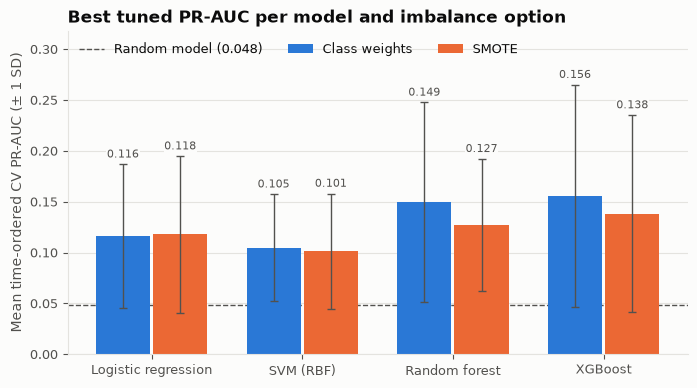

In [7]:
MODELS = ['Logistic regression', 'SVM (RBF)', 'Random forest', 'XGBoost']
IMB = ['Class weights', 'SMOTE']
IMB_COLORS = {'Class weights': CATEGORICAL[0], 'SMOTE': CATEGORICAL[1]}
res_idx = results.set_index(['model', 'imbalance'])

def grouped_bars(ax, mean_col, std_col, fmt, ref=None, ref_label=None):
    x = np.arange(len(MODELS)); w = 0.36
    for j, imb in enumerate(IMB):
        means = [res_idx.loc[(m, imb), mean_col] for m in MODELS]
        stds = [res_idx.loc[(m, imb), std_col] for m in MODELS]
        pos = x + (j - 0.5) * (w + 0.02)
        ax.bar(pos, means, width=w, color=IMB_COLORS[imb], label=imb, zorder=2)
        ax.errorbar(pos, means, yerr=stds, fmt='none', ecolor=REF_LINE_COLOR, elinewidth=1, capsize=3, zorder=3)
        for p, v, s in zip(pos, means, stds):
            ax.annotate(fmt.format(v), (p, v + s), xytext=(0, 3), textcoords='offset points',
                        ha='center', va='bottom', fontsize=8, color=TEXT_SECONDARY, zorder=4,
                        bbox=dict(facecolor=SURFACE, edgecolor='none', pad=0.5))
    if ref is not None:
        ax.axhline(ref, color=REF_LINE_COLOR, linestyle='--', linewidth=1, label=ref_label, zorder=1)
    ax.set_xticks(x, MODELS)
    ax.grid(axis='x', visible=False)

fig, ax = plt.subplots(figsize=(8, 4.2))
grouped_bars(ax, 'pr_auc_mean', 'pr_auc_std', '{:.3f}', ref=val_prevalence, ref_label=f'Random model ({val_prevalence:.3f})')
ax.set_ylim(0, (results['pr_auc_mean'] + results['pr_auc_std']).max() * 1.2)
ax.set_ylabel('Mean time-ordered CV PR-AUC (± 1 SD)')
ax.set_title('Best tuned PR-AUC per model and imbalance option')
ax.legend(loc='upper left', ncol=3)
save_fig(fig, '04_cv_pr_auc_by_model')
plt.show()

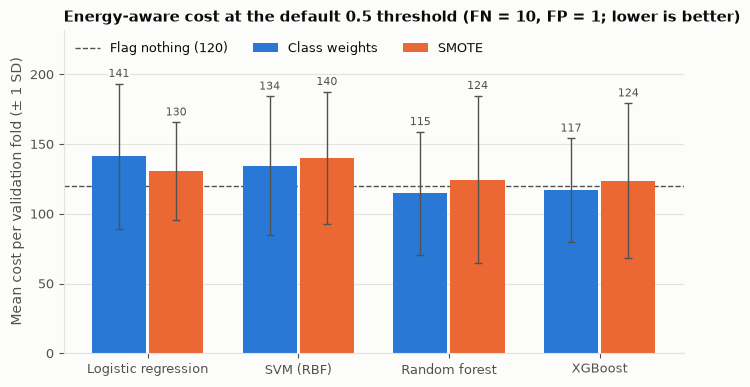

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
grouped_bars(ax, 'cost_mean', 'cost_std', '{:.0f}', ref=cost_flag_nothing,
             ref_label=f'Flag nothing ({cost_flag_nothing:.0f})')
ax.set_ylim(0, max((results['cost_mean'] + results['cost_std']).max(), cost_flag_nothing) * 1.2)
ax.set_ylabel('Mean cost per validation fold (± 1 SD)')
ax.set_title(f'Energy-aware cost at the default 0.5 threshold (FN = {DEFAULT_COST_FN:g}, FP = {DEFAULT_COST_FP:g}; lower is better)',
             fontsize=11)
ax.legend(loc='upper left', ncol=3)
save_fig(fig, '04_cv_cost_by_model')
plt.show()

In [9]:
# Over-fitting check: training-fold vs validation-fold PR-AUC for each best candidate
gap = results[['model', 'imbalance', 'train_pr_auc_mean', 'pr_auc_mean']].copy()
gap['gap'] = gap['train_pr_auc_mean'] - gap['pr_auc_mean']
print(gap.round(3).to_string(index=False))

              model     imbalance  train_pr_auc_mean  pr_auc_mean   gap
            XGBoost Class weights              0.609        0.156 0.453
      Random forest Class weights              0.810        0.149 0.661
            XGBoost         SMOTE              0.638        0.138 0.500
      Random forest         SMOTE              0.923        0.127 0.796
Logistic regression         SMOTE              0.371        0.118 0.253
Logistic regression Class weights              0.390        0.116 0.274
          SVM (RBF) Class weights              0.429        0.105 0.324
          SVM (RBF)         SMOTE              0.391        0.101 0.290


In [10]:
# Compare with the earlier shuffled-CV tuning (kept in outputs/04_cv_results_shuffled_cv.csv)
old_path = OUTPUTS_DIR / '04_cv_results_shuffled_cv.csv'
if old_path.exists():
    old = pd.read_csv(old_path).set_index(['model', 'imbalance'])
    cmp = results.set_index(['model', 'imbalance'])[['pr_auc_mean', 'roc_auc_mean']].join(
        old[['pr_auc_mean', 'roc_auc_mean']], rsuffix='_shuffled')
    cmp = cmp[['pr_auc_mean_shuffled', 'pr_auc_mean', 'roc_auc_mean_shuffled', 'roc_auc_mean']]
    cmp.columns = ['PR-AUC shuffled CV', 'PR-AUC time-ordered CV', 'ROC-AUC shuffled CV', 'ROC-AUC time-ordered CV']
    print(cmp.round(3).to_string())

                                   PR-AUC shuffled CV  PR-AUC time-ordered CV  ROC-AUC shuffled CV  ROC-AUC time-ordered CV
model               imbalance                                                                                              
XGBoost             Class weights               0.252                   0.156                0.723                    0.659
Random forest       Class weights               0.243                   0.149                0.748                    0.623
XGBoost             SMOTE                       0.264                   0.138                0.719                    0.628
Random forest       SMOTE                       0.229                   0.127                0.736                    0.622
Logistic regression SMOTE                       0.197                   0.118                0.723                    0.589
                    Class weights               0.208                   0.116                0.722                    0.579
SVM (RBF

**Reading the results**

- **Honest scores are much lower.** With time-ordered CV, PR-AUC is 0.10–0.16 (a random model scores 0.048 on
  these validation folds) and ROC-AUC 0.55–0.66. Shuffled CV had given 0.20–0.26 and 0.66–0.75. The new range
  matches what the models actually achieved on the later test wafers in 05, so these are the numbers to trust.
- **Tree ensembles still lead:** XGBoost (0.156) and random forest (0.149), both with class weights. Logistic
  regression and SVM are only slightly better than random (ROC-AUC below 0.6).
- **Class weights now beat SMOTE** for XGBoost, random forest and SVM; logistic regression is a tie
  (0.118 vs 0.116). Class weights are also simpler, so they are the better choice here.
- **Tuning for the future picks much simpler models:** XGBoost with depth-2 trees and a low learning rate,
  random forest with depth 4 and at least 9 wafers per leaf, logistic regression with a strong L1 penalty.
  Over-fitting shrinks accordingly (XGBoost training PR-AUC 0.61, down from 1.0 with shuffled CV).
- **At the default 0.5 threshold only the two tree models beat "flag nothing"** on energy cost
  (115 and 117 vs 120 per fold); threshold tuning in 05 is essential.
- Fold-to-fold SDs (0.05–0.11) remain large, partly because the first validation fold has 20 fails and the
  others 8–11, so differences of a few hundredths are not meaningful.

## 5. Save the best model per algorithm

For each algorithm we keep the imbalance option with the higher CV PR-AUC. `RandomizedSearchCV` has already
refitted that pipeline on the **full training set**, so each saved file is a complete model:
**raw 590 sensors in → fail probability out** (preprocessing, feature selection and classifier included;
SMOTE is skipped automatically at prediction time).

In [11]:
FILE_NAMES = {'Logistic regression': 'logistic_regression', 'SVM (RBF)': 'svm_rbf',
              'Random forest': 'random_forest', 'XGBoost': 'xgboost'}
best_per_model = results.loc[results.groupby('model')['pr_auc_mean'].idxmax()].sort_values('pr_auc_mean', ascending=False)

manifest = {'random_state': RANDOM_STATE, 'cv': 'TimeSeriesSplit(4) (time-ordered, expanding window) on the training set',
            'scoring': 'average_precision (PR-AUC)', 'n_iter': N_ITER, 'models': {}}
for _, row in best_per_model.iterrows():
    est = searches[(row['model'], row['imbalance'])].best_estimator_
    est.memory = None                                   # drop the temporary cache reference before saving
    path = MODELS_DIR / f"{FILE_NAMES[row['model']]}.joblib"
    joblib.dump(est, path)

    # The final refit must use exactly the 20 features chosen in notebook 03
    kept = np.array(est.named_steps['drop_correlated'].keep_)
    used = sorted(kept[est.named_steps['select'].get_support()])
    assert used == sorted(fs['selected_features']), 'feature mismatch with notebook 03'

    manifest['models'][row['model']] = {
        'file': f'outputs/models/{path.name}', 'imbalance': row['imbalance'],
        'cv_pr_auc_mean': round(row['pr_auc_mean'], 4), 'cv_pr_auc_std': round(row['pr_auc_std'], 4),
        'cv_roc_auc_mean': round(row['roc_auc_mean'], 4), 'best_params': json.loads(row['best_params'])}
    print(f"Saved {path.relative_to(ROOT)}  ({row['imbalance']}, CV PR-AUC {row['pr_auc_mean']:.3f}, "
          f"{path.stat().st_size / 1024:.0f} KB)")

overall = best_per_model.iloc[0]
manifest['best_overall'] = overall['model']
(MODELS_DIR / 'best_models.json').write_text(json.dumps(manifest, indent=2))
print('Saved outputs/models/best_models.json')
print('All saved models use exactly the 20 features from notebook 03.')

Saved outputs\models\xgboost.joblib  (Class weights, CV PR-AUC 0.156, 194 KB)


Saved outputs\models\random_forest.joblib  (Class weights, CV PR-AUC 0.149, 954 KB)
Saved outputs\models\logistic_regression.joblib  (SMOTE, CV PR-AUC 0.118, 105 KB)
Saved outputs\models\svm_rbf.joblib  (Class weights, CV PR-AUC 0.105, 221 KB)
Saved outputs/models/best_models.json
All saved models use exactly the 20 features from notebook 03.


In [12]:
# Sanity check: reload one model and predict on raw training rows
for name in best_per_model['model']:
    m = joblib.load(MODELS_DIR / f'{FILE_NAMES[name]}.joblib')
    if hasattr(m, 'predict_proba'):
        s, kind = m.predict_proba(X_train.iloc[:5])[:, 1], 'P(fail)'
    else:   # SVC without probability=True: use the decision score (05 can calibrate it)
        s, kind = m.decision_function(X_train.iloc[:5]), 'decision score'
    print(f'Reloaded {name:<20} {kind} for 5 training wafers: {np.round(s, 3)}')

shutil.rmtree(CACHE_DIR, ignore_errors=True)     # remove the temporary preprocessing cache

Reloaded XGBoost              P(fail) for 5 training wafers: [0.436 0.494 0.735 0.591 0.402]


Reloaded Random forest        P(fail) for 5 training wafers: [0.481 0.433 0.803 0.513 0.407]
Reloaded Logistic regression  P(fail) for 5 training wafers: [0.5   0.542 0.9   0.819 0.092]


Reloaded SVM (RBF)            decision score for 5 training wafers: [ 0.46   0.383  1.288  0.285 -1.707]


### Summary

In [13]:
print(f'Best overall by CV PR-AUC: {overall["model"]} with {overall["imbalance"]} '
      f'(PR-AUC {overall["pr_auc_mean"]:.3f} ± {overall["pr_auc_std"]:.3f}, ROC-AUC {overall["roc_auc_mean"]:.3f})\n')
w = max(len(m) for m in MODELS)
for _, r in best_per_model.iterrows():
    print(f"{r['model']:<{w}}  {r['imbalance']:<14} PR-AUC {r['pr_auc_mean']:.3f} ± {r['pr_auc_std']:.3f}   "
          f"recall {r['recall_mean']:.2f}   cost {r['cost_mean']:.1f}")

Best overall by CV PR-AUC: XGBoost with Class weights (PR-AUC 0.156 ± 0.109, ROC-AUC 0.659)

XGBoost              Class weights  PR-AUC 0.156 ± 0.109   recall 0.45   cost 116.8
Random forest        Class weights  PR-AUC 0.149 ± 0.098   recall 0.16   cost 114.8
Logistic regression  SMOTE          PR-AUC 0.118 ± 0.077   recall 0.37   cost 130.5
SVM (RBF)            Class weights  PR-AUC 0.105 ± 0.052   recall 0.29   cost 134.5


**Next (05_Evaluation):** load the four saved models, tune each one's decision threshold for minimum energy cost
on out-of-fold training predictions, then evaluate once on the untouched time-ordered test set.